In [1]:
import pandas as pd
import numpy as np

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 150)

df = pd.read_csv('../data/processed/spain_top50_staged.csv', parse_dates=['date'])
keys = ['song_key', 'artist_key', 'run_id']
df = df.sort_values(keys + ['date'])

print(df['popularity'].describe().round(1))

# Day-to-day change in popularity within a run
step = df.groupby(keys)['popularity'].diff().dropna()
print("\nDay-to-day popularity change:")
print(step.describe().round(2))
print(f"Share of days with no change: {(step == 0).mean():.0%}")

# Overall link between popularity and chart position (lower position number = better rank)
rho = df['popularity'].rank().corr(df['position'].rank())
print(f"\nSpearman, popularity vs position (all song-days): {rho:.2f}")

count    27750.0
mean        81.1
std         10.1
min          0.0
25%         76.0
50%         82.0
75%         87.0
max        100.0
Name: popularity, dtype: float64

Day-to-day popularity change:
count    26747.00
mean         0.34
std          4.11
min        -92.00
25%          0.00
50%          0.00
75%          0.00
max         85.00
Name: popularity, dtype: float64
Share of days with no change: 82%

Spearman, popularity vs position (all song-days): -0.24


In [2]:
df['pop_change'] = df.groupby(keys)['popularity'].diff()
df['next_change'] = -df.groupby(keys)['popularity'].diff(-1)   # change from this day to the next

print(f"Rows with popularity = 0: {(df['popularity'] == 0).sum()}")
print(f"Rows below 40: {(df['popularity'] < 40).sum()}")

for cut in (10, 20, 40):
    print(f"Day-to-day changes of {cut}+ points: {(df['pop_change'].abs() >= cut).sum()}")

dip = (df['pop_change'] <= -20) & (df['next_change'] >= 20)
print(f"\nOne-day dips of 20+ that rebound by 20+ the next day: {dip.sum()}")

low = df[df['popularity'] < 40]
print("\nDates with the most rows below 40:")
print(low.groupby('date').size().sort_values(ascending=False).head(8))

print("\nLowest-popularity rows:")
print(df.nsmallest(10, 'popularity')[['date', 'song', 'position', 'popularity']])

Rows with popularity = 0: 106
Rows below 40: 164
Day-to-day changes of 10+ points: 146
Day-to-day changes of 20+ points: 120
Day-to-day changes of 40+ points: 83

One-day dips of 20+ that rebound by 20+ the next day: 8

Dates with the most rows below 40:
date
2024-10-14    22
2024-08-30    15
2025-08-24    14
2025-06-16     9
2024-11-25     8
2024-10-01     8
2024-09-30     8
2024-12-02     7
dtype: int64

Lowest-popularity rows:
           date                                    song  position  popularity
330  2024-12-02                                50 PALOS        38           0
669  2024-10-14                                 ACHO PR        15           0
729  2025-08-24                                 ADIVINO        10           0
964  2024-12-02                                 ALAKRAN        24           0
1892 2025-08-24  AUNQUE LLEGUE OTRO (feat. Jay Wheeler)        23           0
1895 2024-08-30                              AYER Y HOY        23           0
1897 2024-07-09     

In [3]:
starts = df[df['day_in_run'] == 1]
print(f"Runs starting with popularity below 40: {(starts['popularity'] < 40).sum()} of {len(starts)}")

print("\nZero-popularity rows by day in run (6 = day 6 or later):")
print(df[df['popularity'] == 0]['day_in_run'].clip(upper=6).value_counts().sort_index())

big = df[df['pop_change'].abs() >= 20]
print(f"\nBig jumps up: {(big['pop_change'] > 0).sum()}   big drops: {(big['pop_change'] < 0).sum()}")
print("Album share among rows below 40:", (df[df['popularity'] < 40]['album_type'] == 'album').mean().round(2))

print("\nThe largest drops:")
print(df[df['pop_change'] <= -40][['date', 'song', 'position', 'day_in_run', 'popularity', 'pop_change']].head(6))

Runs starting with popularity below 40: 122 of 1003

Zero-popularity rows by day in run (6 = day 6 or later):
day_in_run
1    95
2     7
6     4
Name: count, dtype: int64

Big jumps up: 103   big drops: 17
Album share among rows below 40: 0.77

The largest drops:
            date                         song  position  day_in_run  popularity  pop_change
2615  2025-04-07             Beautiful Things        22          24          59       -41.0
3103  2025-02-25               Buscando Money        10          24           0       -87.0
4232  2024-08-26                    COCO LOCO        13          57           0       -87.0
5721  2025-07-20  Cuando Te Vi | CROSSOVER #5        18          15          19       -62.0
9615  2025-10-13                        FRIKI        10         155          33       -42.0
11182 2024-07-26                        K-POP        31           4           4       -84.0


In [4]:
# Popularity: zeros and one-day dips that rebound -> missing
dip = (df['pop_change'] <= -20) & (df['next_change'] >= 20)
df['pop_clean'] = df['popularity'].astype(float)
df.loc[dip | (df['popularity'] == 0), 'pop_clean'] = np.nan
print(f"Popularity values set to missing: {df['pop_clean'].isna().sum()}")

# Day each run first reached its best rank and its highest cleaned popularity
df['run_best_pos'] = df.groupby(keys)['position'].transform('min')
df['run_max_pop'] = df.groupby(keys)['pop_clean'].transform('max')
rank_day = df[df['position'] == df['run_best_pos']].groupby(keys)['day_in_run'].min().rename('rank_peak_day')
pop_day = df[df['pop_clean'] == df['run_max_pop']].groupby(keys)['day_in_run'].min().rename('pop_peak_day')

runs6 = df.groupby(keys).agg(run_length=('date', 'size'), start=('date', 'min'), end=('date', 'max'),
                             max_pop=('pop_clean', 'max'), min_pop=('pop_clean', 'min'))
runs6 = runs6.join(rank_day).join(pop_day)
runs6['first_pop'] = df[df['day_in_run'] == 1].set_index(keys)['popularity']
runs6['pop_range'] = runs6['max_pop'] - runs6['min_pop']
runs6['lag'] = runs6['pop_peak_day'] - runs6['rank_peak_day']

ok = runs6[(runs6['start'] > df['date'].min()) & (runs6['end'] < df['date'].max()) & (runs6['pop_range'] >= 5)]
print(f"Runs of 14+ days: {(runs6['run_length'] >= 14).sum()}   of which qualify: {(ok['run_length'] >= 14).sum()}")

scenarios = {
    'runs of 14+ days': ok['run_length'] >= 14,
    'runs of 30+ days': ok['run_length'] >= 30,
    '14+ days, excluding low starts': (ok['run_length'] >= 14) & (ok['first_pop'] >= 40),
}
rng = np.random.default_rng(42)
print()
for name, mask in scenarios.items():
    lag = ok.loc[mask, 'lag']
    boot = [np.median(rng.choice(lag.to_numpy(), len(lag))) for _ in range(3000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"{name:32s} n={len(lag):3d}  popularity first: {(lag < 0).mean():4.0%}  "
          f"same day: {(lag == 0).mean():4.0%}  popularity later: {(lag > 0).mean():4.0%}  "
          f"median lag {lag.median():.0f} days [95% CI {lo:.0f}, {hi:.0f}]")

Popularity values set to missing: 112
Runs of 14+ days: 335   of which qualify: 196

runs of 14+ days                 n=196  popularity first:  10%  same day:   2%  popularity later:  88%  median lag 15 days [95% CI 13, 18]
runs of 30+ days                 n=149  popularity first:  12%  same day:   1%  popularity later:  87%  median lag 18 days [95% CI 16, 21]
14+ days, excluding low starts   n=158  popularity first:  12%  same day:   3%  popularity later:  85%  median lag 15 days [95% CI 13, 18]


In [5]:
ok14 = ok[ok['run_length'] >= 14].copy()
print("Day within the run when rank peaked (qualifying 14+ day runs):")
print(ok14['rank_peak_day'].describe().round(1))
print(f"Rank peaked on day 1: {(ok14['rank_peak_day'] == 1).mean():.0%}   "
      f"within first 3 days: {(ok14['rank_peak_day'] <= 3).mean():.0%}")

print("\nOnly runs where rank peaked at least N days in:")
for n_min in (4, 8, 15):
    sub = ok14.loc[ok14['rank_peak_day'] >= n_min, 'lag']
    if len(sub) < 5:
        print(f"rank peak on day {n_min}+  n={len(sub)}  too few runs")
        continue
    boot = [np.median(rng.choice(sub.to_numpy(), len(sub))) for _ in range(3000)]
    lo, hi = np.percentile(boot, [2.5, 97.5])
    print(f"rank peak on day {n_min}+  n={len(sub):3d}  popularity first: {(sub < 0).mean():4.0%}  "
          f"same day: {(sub == 0).mean():4.0%}  later: {(sub > 0).mean():4.0%}  "
          f"median lag {sub.median():.0f} days [95% CI {lo:.0f}, {hi:.0f}]")

Day within the run when rank peaked (qualifying 14+ day runs):
count    196.0
mean      14.8
std       22.1
min        1.0
25%        1.0
50%        7.0
75%       18.0
max      153.0
Name: rank_peak_day, dtype: float64
Rank peaked on day 1: 27%   within first 3 days: 35%

Only runs where rank peaked at least N days in:
rank peak on day 4+  n=128  popularity first:  14%  same day:   2%  later:  84%  median lag 15 days [95% CI 11, 18]
rank peak on day 8+  n= 91  popularity first:  18%  same day:   3%  later:  79%  median lag 14 days [95% CI 9, 18]
rank peak on day 15+  n= 61  popularity first:  25%  same day:   5%  later:  70%  median lag 9 days [95% CI 5, 16]


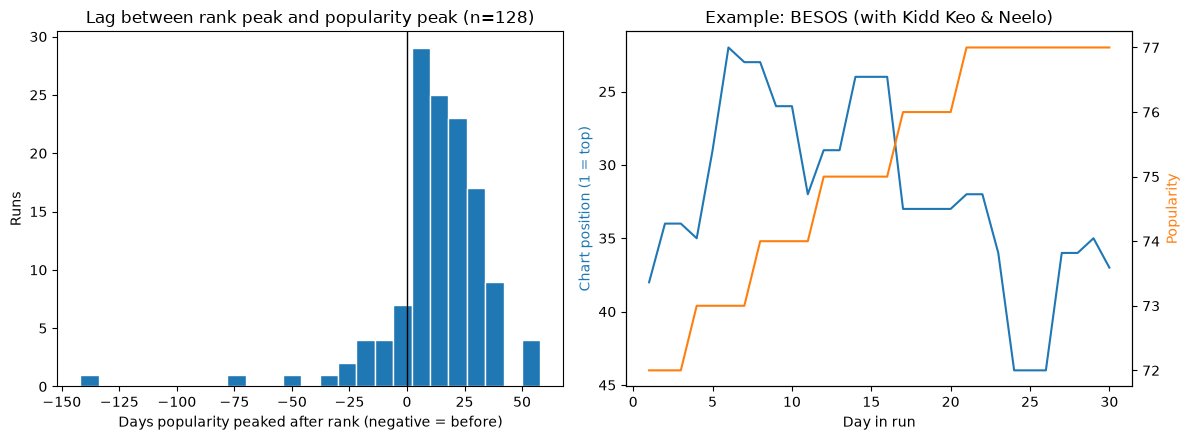

Example run: BESOS (with Kidd Keo & Neelo), lag 15 days, median lag in the group 15 days


In [6]:
import matplotlib.pyplot as plt

sub = ok14[ok14['rank_peak_day'] >= 4]
typical = sub['lag'].median()
cand = sub[sub['run_length'] >= 30]
pick = (cand['lag'] - typical).abs().idxmin()          # (song_key, artist_key, run_id)
ex = df[(df['song_key'] == pick[0]) & (df['artist_key'] == pick[1]) & (df['run_id'] == pick[2])]

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

axes[0].hist(sub['lag'], bins=25, color='tab:blue', edgecolor='white')
axes[0].axvline(0, color='black', linewidth=1)
axes[0].set_xlabel('Days popularity peaked after rank (negative = before)')
axes[0].set_ylabel('Runs')
axes[0].set_title(f'Lag between rank peak and popularity peak (n={len(sub)})')

ax = axes[1]
ax.plot(ex['day_in_run'], ex['position'], color='tab:blue')
ax.invert_yaxis()
ax.set_xlabel('Day in run')
ax.set_ylabel('Chart position (1 = top)', color='tab:blue')
ax2 = ax.twinx()
ax2.plot(ex['day_in_run'], ex['pop_clean'], color='tab:orange')
ax2.set_ylabel('Popularity', color='tab:orange')
ax.set_title(f"Example: {ex['song'].iloc[0]}")

plt.tight_layout()
plt.savefig('../outputs/figures/rank_vs_popularity_timing.png', dpi=150)
plt.show()

print(f"Example run: {ex['song'].iloc[0]}, lag {runs6.loc[pick, 'lag']:.0f} days, median lag in the group {typical:.0f} days")
runs6.reset_index().to_csv('../outputs/tables/popularity_rank_lag.csv', index=False)